<center><h1>Yang_Yuxin_HW4</h1></center>

Name: Yuxin Yang   
USC ID:1505451394

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

In [1]:
import io
import re
import zipfile
import warnings
from urllib.request import urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.special import expit, logit
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize
from sklearn.feature_selection import VarianceThreshold, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score,
    classification_report)
from sklearn.exceptions import ConvergenceWarning
from pandas.plotting import scatter_matrix
from IPython.display import display, Markdown

SEED = 552
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 12)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})

Matplotlib is building the font cache; this may take a moment.


Get the AReM Data Set

In [2]:
url = "https://archive.ics.uci.edu/static/public/366/activity+recognition+system+based+on+multisensor+data+fusion+arem.zip"
with urlopen(url, timeout=60) as response:
    archive = zipfile.ZipFile(io.BytesIO(response.read()))

series_names = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
files = [name for name in archive.namelist()
         if re.fullmatch(r"[^/]+/dataset\d+\.csv", name)]
files.sort(key=lambda name: (name.split("/")[0],
                            int(re.search(r"dataset(\d+)", name).group(1))))
recordings = []
metadata = []
for name in files:
    text = archive.read(name).decode("utf-8-sig")
    lines = [line.strip() for line in text.splitlines()
             if line.strip() and not line.startswith("#")]
    # Handle whitespace-separated records and trailing commas.
    rows = [re.split(r"[,\s]+", line.rstrip(",")) for line in lines]
    data = pd.DataFrame(rows, columns=["time"] + series_names).astype(float)
    missing = sorted(set(np.arange(480) * 250) - set(data["time"]))
    expected_missing = [13500] if name == "sitting/dataset8.csv" else []
    assert missing == expected_missing and len(data) == 480 - len(missing)
    assert data["time"].is_monotonic_increasing and not data["time"].duplicated().any()
    assert np.isfinite(data.to_numpy()).all()
    recordings.append(data[series_names].to_numpy())
    activity = name.split("/")[0]
    dataset_id = int(re.search(r"dataset(\d+)", name).group(1))
    metadata.append([name, activity, dataset_id, len(data)])

metadata = pd.DataFrame(metadata, columns=["file", "activity", "dataset_id", "rows"])
assert len(recordings) == 88
print("Downloaded 88 recordings in 7 activity folders, each with 6 signals.")
display(metadata.groupby("activity").agg(instances=("file", "count"),
                                         min_rows=("rows", "min"), max_rows=("rows", "max")))
print("Source exception: sitting/dataset8.csv has 479 samples; its missing 13,500 ms sample is not imputed.")

Downloaded 88 recordings in 7 activity folders, each with 6 signals.


,instances,min_rows,max_rows
activity,,,
bending1,7,480,480
bending2,6,480,480
cycling,15,480,480
lying,15,480,480
sitting,15,479,480
standing,15,480,480
walking,15,480,480


Source exception: sitting/dataset8.csv has 479 samples; its missing 13,500 ms sample is not imputed.


### (b) Splitting Data

In [3]:
test_limit = np.where(metadata["activity"].isin(["bending1", "bending2"]), 2, 3)
is_test = metadata["dataset_id"].to_numpy() <= test_limit
train_ids = np.flatnonzero(~is_test)
test_ids = np.flatnonzero(is_test)
y_train = metadata.loc[train_ids, "activity"].to_numpy()
y_test = metadata.loc[test_ids, "activity"].to_numpy()
# Binary positive class: bending1 OR bending2.
y_binary = np.isin(y_train, ["bending1", "bending2"]).astype(int)
y_binary_test = np.isin(y_test, ["bending1", "bending2"]).astype(int)
assert len(train_ids) == 69 and len(test_ids) == 19
metadata["split"] = np.where(is_test, "test", "train")
display(pd.crosstab(metadata["activity"], metadata["split"]))
print("Binary train counts (other, bending):", np.bincount(y_binary))

split,test,train
activity,,
bending1,2,5
bending2,2,4
cycling,3,12
lying,3,12
sitting,3,12
standing,3,12
walking,3,12


Binary train counts (other, bending): [60  9]


### (c) Feature Extraction

For each segment of each signal, I extract minimum, maximum, mean, median, sample standard deviation, first quartile (`q1`), and third quartile (`q3`). Therefore each recording has $42l$ features. No information is shared between recordings during extraction.

In [4]:
statistics = ["min", "max", "mean", "median", "std", "q1", "q3"]
chosen_statistics = ["mean", "std", "q3"]

def extract_features(l):
    """One row per recording; l nearly equal, consecutive pieces per signal."""
    rows = []
    for recording in recordings:
        row = {}
        for part, segment in enumerate(np.array_split(recording, l), start=1):
            for signal in range(6):
                x = segment[:, signal]
                values = [x.min(), x.max(), x.mean(), np.median(x),
                          x.std(ddof=1), np.quantile(x, 0.25), np.quantile(x, 0.75)]
                for statistic, value in zip(statistics, values):
                    row[f"{statistic}_s{signal + 1}_part{part}"] = value
        rows.append(row)
    table = pd.DataFrame(rows)
    assert table.shape == (88, 42 * l)
    assert np.isfinite(table.to_numpy()).all()
    return table

# Deterministic per-recording extraction does not learn from other recordings.
features = {l: extract_features(l) for l in range(1, 21)}
X_train = {l: table.iloc[train_ids].reset_index(drop=True) for l, table in features.items()}
X_test = {l: table.iloc[test_ids].reset_index(drop=True) for l, table in features.items()}
print("For l=1:", X_train[1].shape, "training;", X_test[1].shape, "test")
print("For l=20:", X_train[20].shape, "training; number of recordings stays 69.")
display(X_train[1].head().round(3))

For l=1: (69, 42) training; (19, 42) test
For l=20: (69, 840) training; number of recordings stays 69.


,min_s1_part1,max_s1_part1,mean_s1_part1,median_s1_part1,std_s1_part1,q1_s1_part1,...,max_s6_part1,mean_s6_part1,median_s6_part1,std_s6_part1,q1_s6_part1,q3_s6_part1
0,35.00,47.40,43.954,44.33,1.559,43.00,...,1.79,0.493,0.43,0.514,0.00,0.94
1,33.00,47.75,42.180,43.50,3.671,39.15,...,2.18,0.614,0.50,0.524,0.00,1.00
2,33.00,45.75,41.678,41.75,2.243,41.33,...,1.79,0.383,0.43,0.389,0.00,0.50
3,37.00,48.00,43.455,43.25,1.386,42.50,...,5.26,0.680,0.50,0.623,0.43,0.87
4,36.25,48.00,43.969,44.50,1.618,43.31,...,2.96,0.555,0.49,0.488,0.00,0.83


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

I retain mean, standard deviation, and third quartile from HW3. They describe overall level, variability, and a high signal level that is less sensitive to outliers than maximum. The nine plotted features come from signals 1, 2, and 6. Only training recordings are shown.

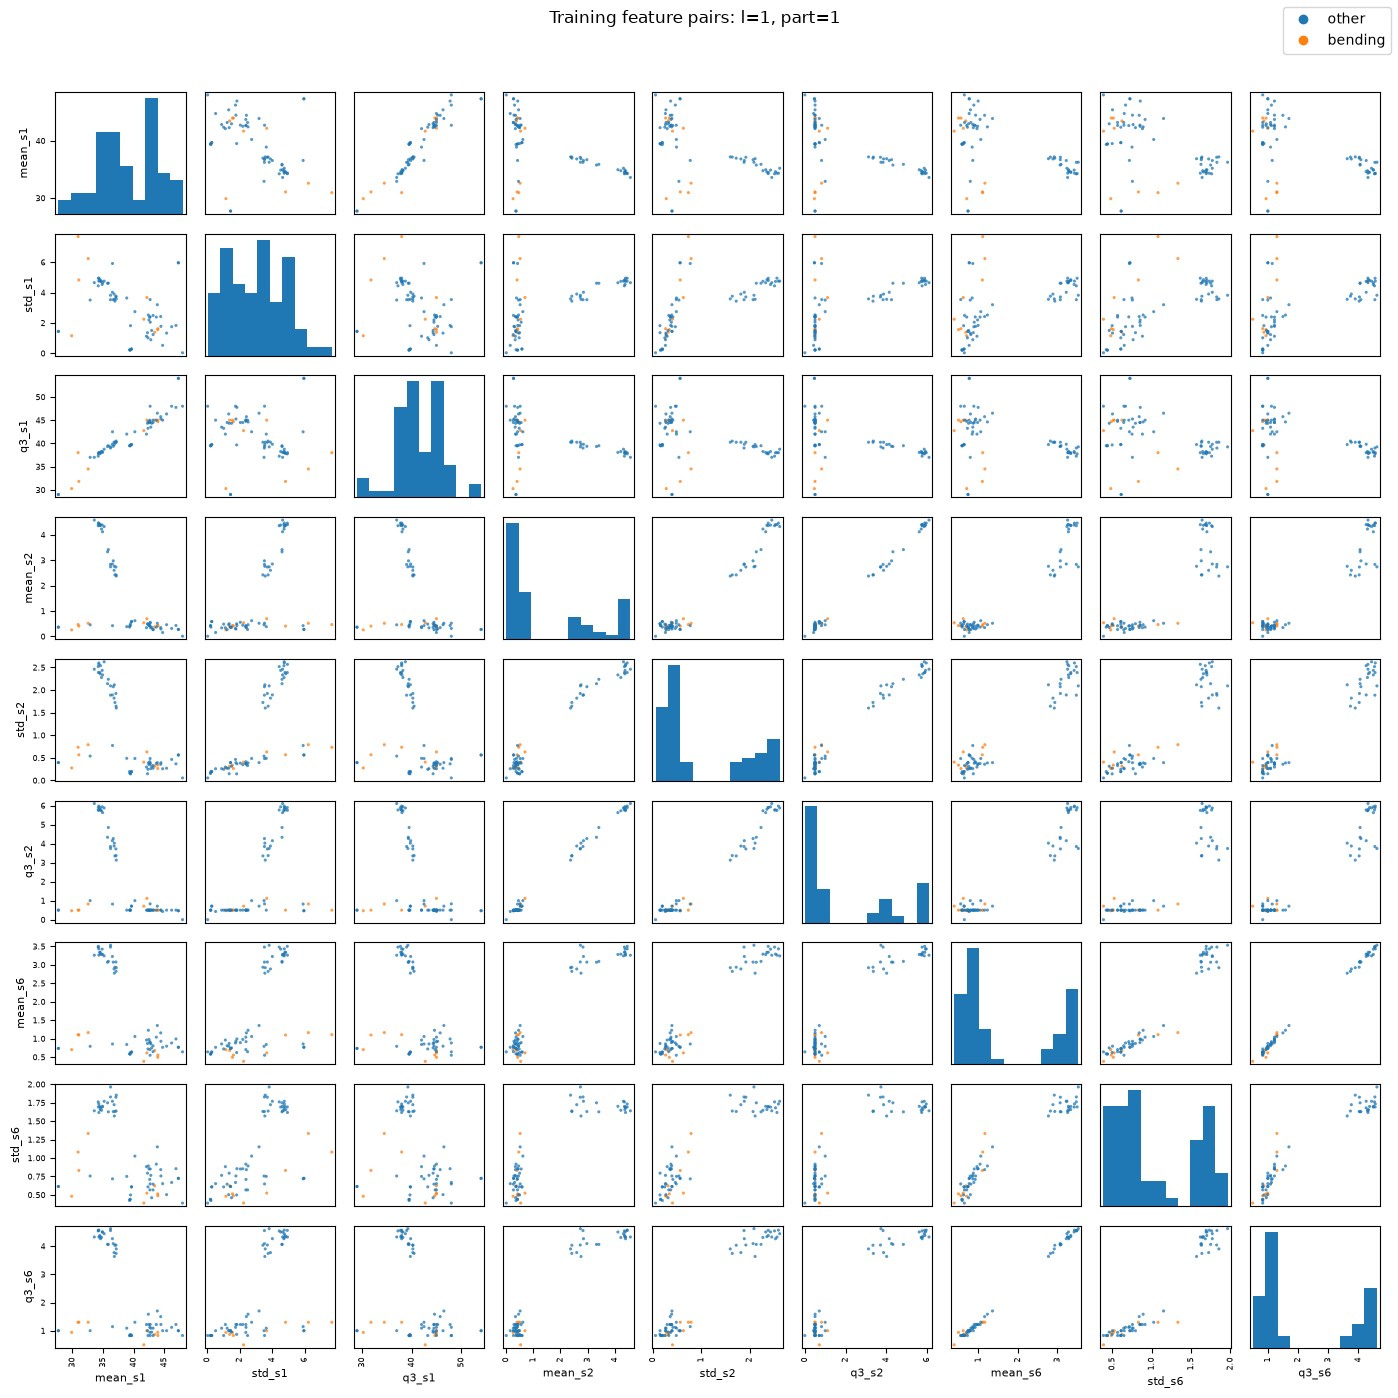

In [5]:
def plot_feature_pairs(l, part):
    columns = [f"{stat}_s{signal}_part{part}"
               for signal in [1, 2, 6] for stat in chosen_statistics]
    data = X_train[l][columns].copy()
    data.columns = [name.replace(f"_part{part}", "") for name in columns]
    colors = np.where(y_binary == 1, "tab:orange", "tab:blue")
    axes = scatter_matrix(data, figsize=(14, 14), color=colors,
                          alpha=0.75, s=20, diagonal="hist")
    for ax in axes.flat:
        ax.tick_params(labelsize=6)
        ax.xaxis.label.set_size(8)
        ax.yaxis.label.set_size(8)
    handles = [plt.Line2D([], [], marker="o", linestyle="", color=color, label=label)
               for color, label in [("tab:blue", "other"), ("tab:orange", "bending")]]
    fig = axes[0, 0].figure
    fig.legend(handles=handles, loc="upper right")
    fig.suptitle(f"Training feature pairs: l={l}, part={part}", y=0.995)
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

plot_feature_pairs(1, 1)

#### ii. Split Plots

Each recording is split into two consecutive parts of almost equal length (240/240 samples, or 240/239 for the one shorter file). There are now 12 signal segments per recording. Separate matrices below show the same nine features for each half, keeping labels readable.

**Observation:** The broad pattern remains similar after splitting. Bending records tend to have low mean, standard deviation, and third quartile for signals 2 and 6, but they overlap with some non-bending records. Splitting changes some individual locations, especially variability in signal 1, and describes differences between the first and second halves. I do not see a consistently large improvement in separation across these panels; cross-validation, rather than visual inspection alone, should decide whether splitting helps.

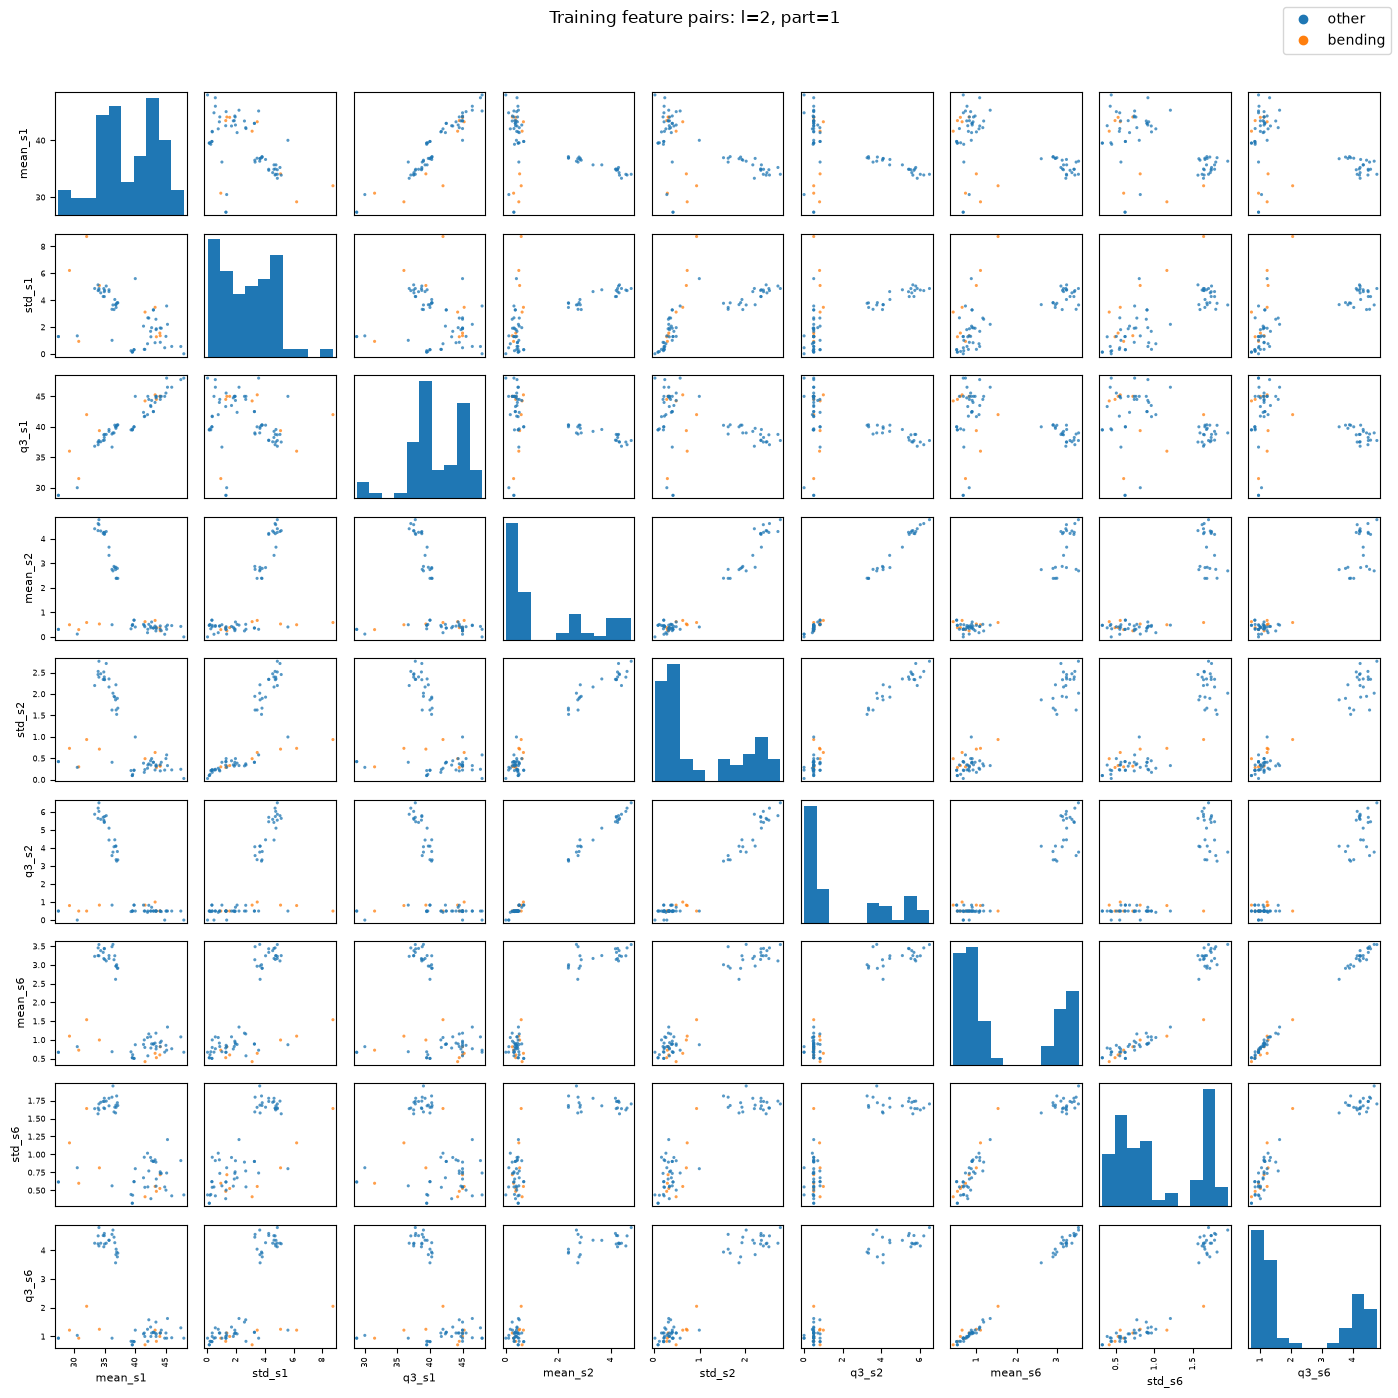

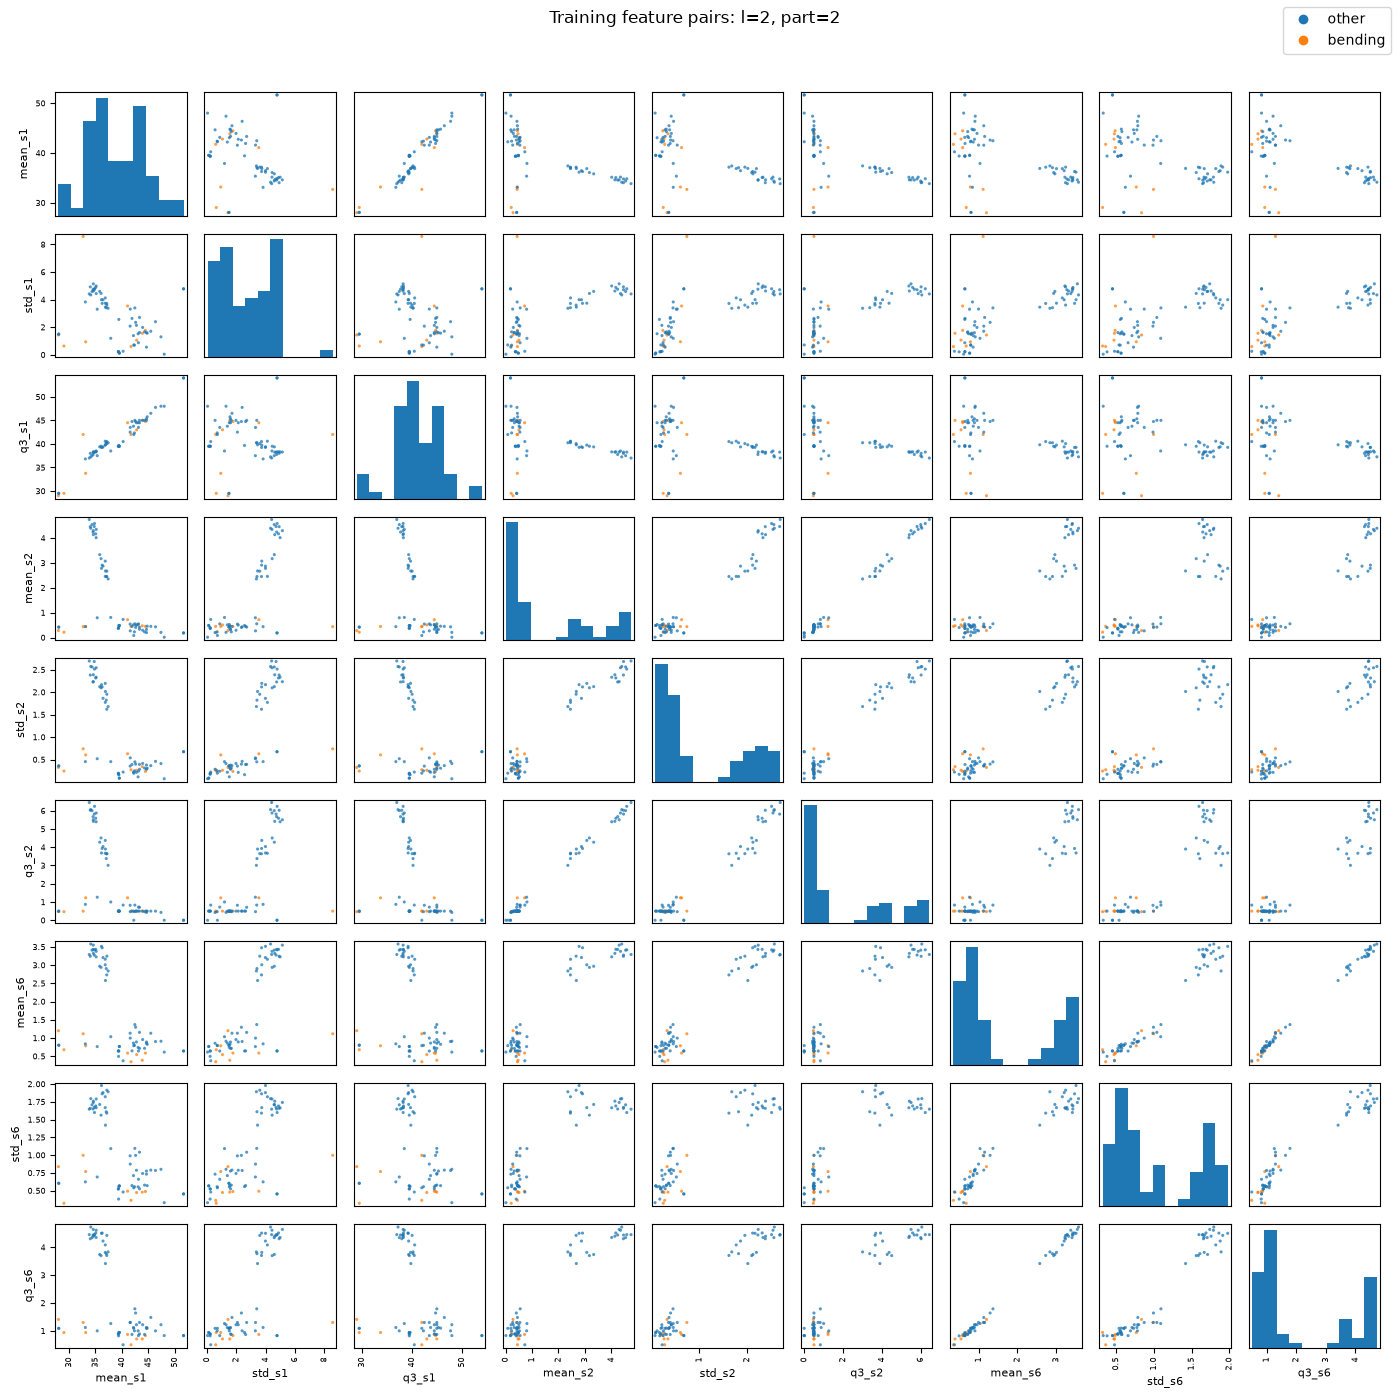

In [6]:
plot_feature_pairs(2, 1)
plot_feature_pairs(2, 2)

#### iii. Time Series Segments

I use the assignment's **RFE alternative** to p-value-based pruning. All seven statistics are candidates. For each $l=1,\ldots,20$, the grid searches $p\in\{1,3,5,10,20\}$ selected features. This is an explicitly limited feature-count grid, rather than an exhaustive search over all $42l$ counts. RFE removes half of the remaining features at each step to keep runtime manageable.

**Correct CV:** use stratified 5-fold splits of whole training recordings; fit constant-feature removal, scaling, RFE, and logistic regression inside each fold. Stratification approximately preserves the 9 bending / 60 other ratio. Per-recording segmentation can be precomputed because it uses no labels or cross-recording estimates.

**Wrong CV:** select features or fit a scaler on all training records before CV, split segments of one recording across folds, or use the test set to select $l$, $p$, or $C$.

All candidates use the same folds and accuracy score. Ties retain the first candidate (smaller $l$, then smaller grid parameter). These CV scores are tuning scores and can be optimistic after searching many candidates; the held-out test set is the final check. A large $C=10^6$ makes the L2 penalty negligible, as allowed in the assignment.

Best l: 1 Parameters: {'rfe__n_features_to_select': 3}
Best mean CV accuracy: 0.9857


,l,rfe__n_features_to_select,CV_accuracy,CV_std
1,1,3,0.985714,0.028571
2,1,5,0.971429,0.034993
3,1,10,0.957143,0.057143
6,2,3,0.957143,0.057143
7,2,5,0.957143,0.057143
11,3,3,0.957143,0.034993
16,4,3,0.957143,0.057143
26,6,3,0.957143,0.034993
89,18,20,0.957143,0.057143
94,19,20,0.957143,0.057143


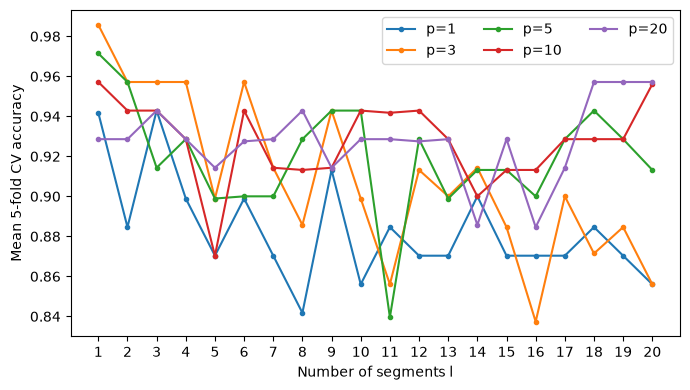

In [7]:
cv_binary = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_multi = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)
# bending2 has only 4 training records: 4 folds keep every class in each fold.
C_grid = [0.01, 0.1, 1, 10, 100]


def search_segments(estimator, parameter_grid, y, cv):
    """Tune l plus pipeline parameters using training data only."""
    rows = []
    best = None
    for l in range(1, 21):
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)
            search = GridSearchCV(clone(estimator), parameter_grid, cv=cv,
                                  scoring="accuracy", n_jobs=1, error_score="raise")
            search.fit(X_train[l], y)
        convergence_count = sum(issubclass(w.category, ConvergenceWarning) for w in caught)
        other_warnings = sorted({str(w.message) for w in caught
                                 if not issubclass(w.category, ConvergenceWarning)})
        if other_warnings:
            print("Warnings at l=", l, other_warnings)
        for index, params in enumerate(search.cv_results_["params"]):
            rows.append({"l": l, **params,
                         "CV_accuracy": search.cv_results_["mean_test_score"][index],
                         "CV_std": search.cv_results_["std_test_score"][index]})
        if best is None or search.best_score_ > best["score"] + 1e-12:
            best = {"l": l, "model": search.best_estimator_,
                    "score": search.best_score_, "params": search.best_params_}
        if convergence_count:
            print(f"l={l}: {convergence_count} fits reached max_iter; scores are approximate.")
    table = pd.DataFrame(rows)
    print("Best l:", best["l"], "Parameters:", best["params"])
    print("Best mean CV accuracy:", round(best["score"], 4))
    display(table.sort_values("CV_accuracy", ascending=False, kind="stable").head(10))
    return best, table

rfe_pipeline = Pipeline([
    ("nonconstant", VarianceThreshold()),
    ("scale", StandardScaler()),
    ("rfe", RFE(LogisticRegression(C=1e6, solver="lbfgs", max_iter=2000), step=0.5)),
    ("model", LogisticRegression(C=1e6, solver="lbfgs", max_iter=2000))
])
best_rfe, rfe_results = search_segments(
    rfe_pipeline, {"rfe__n_features_to_select": [1, 3, 5, 10, 20]}, y_binary, cv_binary)

plt.figure(figsize=(7, 4))
for p, group in rfe_results.groupby("rfe__n_features_to_select"):
    plt.plot(group["l"], group["CV_accuracy"], marker=".", label=f"p={p}")
plt.xlabel("Number of segments l")
plt.ylabel("Mean 5-fold CV accuracy")
plt.xticks(range(1, 21))
plt.legend(ncol=3)
plt.tight_layout()
plt.show()

#### iv. Training Confusion Matrix, ROC, Parameters, and p-values

Class 1 is bending and class 0 is other. Training metrics are resubstitution metrics, not estimates of generalization. Coefficients below apply to **standardized selected features**. Wald p-values are also computed after selection for reporting; they are not valid selection-adjusted inference. Under separation, finite unpenalized estimates and meaningful ordinary Wald p-values do not exist, so numerical p-values must not be interpreted as evidence of significance.

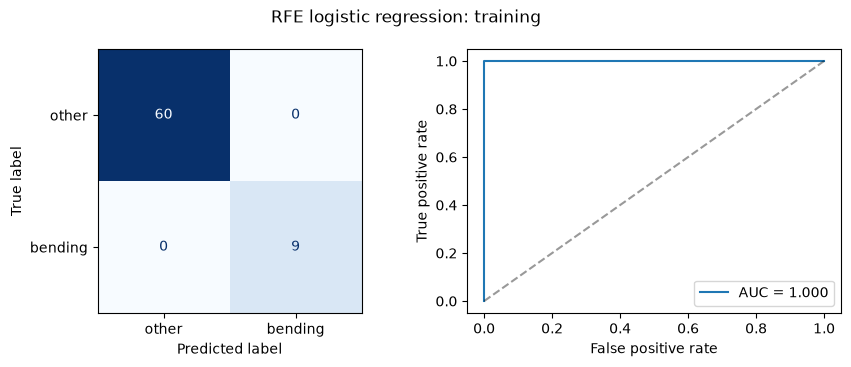

{'accuracy': 1.0, 'balanced_accuracy': 1.0, 'AUC': 1.0}
Selected features: ['q3_s1_part1', 'min_s5_part1', 'max_s5_part1']
Selected features admit strict separation: True
GLM warnings: ['Perfect separation or prediction detected, parameter may not be identified']


,coefficient,unpenalized_GLM_coefficient,formal_Wald_p_value
intercept,-26.238408,-100.233847,0.998935
q3_s1_part1,-7.781374,-28.456474,0.999739
min_s5_part1,13.076400,51.140025,0.999719
max_s5_part1,16.391837,61.622991,0.999549


Strict separation: the displayed GLM coefficients/p-values are numerical artifacts, not valid finite-MLE inference.


In [8]:
def binary_report(y, probability, title):
    prediction = (probability >= 0.5).astype(int)
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.7))
    ConfusionMatrixDisplay.from_predictions(
        y, prediction, labels=[0, 1], display_labels=["other", "bending"],
        ax=axes[0], colorbar=False, cmap="Blues")
    fpr, tpr, _ = roc_curve(y, probability)
    auc = roc_auc_score(y, probability)
    axes[1].plot(fpr, tpr, label=f"AUC = {auc:.3f}")
    axes[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
    axes[1].set(xlabel="False positive rate", ylabel="True positive rate")
    axes[1].legend(loc="lower right")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    result = {"accuracy": accuracy_score(y, prediction),
              "balanced_accuracy": balanced_accuracy_score(y, prediction), "AUC": auc}
    print(result)
    return result

l_rfe = best_rfe["l"]
rfe_model = best_rfe["model"]
rfe_train_metrics = binary_report(y_binary,
    rfe_model.predict_proba(X_train[l_rfe])[:, 1], "RFE logistic regression: training")

names = X_train[l_rfe].columns[rfe_model.named_steps["nonconstant"].get_support()]
selected_names = names[rfe_model.named_steps["rfe"].get_support()]
Z_train = rfe_model[:-1].transform(X_train[l_rfe])
Z_test = rfe_model[:-1].transform(X_test[l_rfe])
parameter_table = pd.DataFrame({
    "coefficient": np.r_[rfe_model.named_steps["model"].intercept_,
                         rfe_model.named_steps["model"].coef_.ravel()]},
    index=["intercept"] + list(selected_names))

# Fit an unpenalized binomial GLM on the same standardized selected features.
with warnings.catch_warnings(record=True) as glm_warnings:
    warnings.simplefilter("always")
    glm_result = sm.GLM(y_binary, sm.add_constant(Z_train),
                        family=sm.families.Binomial()).fit(maxiter=100)
parameter_table["unpenalized_GLM_coefficient"] = glm_result.params
parameter_table["formal_Wald_p_value"] = glm_result.pvalues
margin = (2 * y_binary - 1) * rfe_model.decision_function(X_train[l_rfe])
separated = bool(np.all(margin > 0))
print("Selected features:", list(selected_names))
print("Selected features admit strict separation:", separated)
print("GLM warnings:", sorted({str(w.message) for w in glm_warnings}))
display(parameter_table)
if separated:
    print("Strict separation: the displayed GLM coefficients/p-values are numerical artifacts, not valid finite-MLE inference.")
else:
    print("Wald p-values are exploratory; they ignore the preceding data-dependent feature selection.")

#### v. Test Classifier

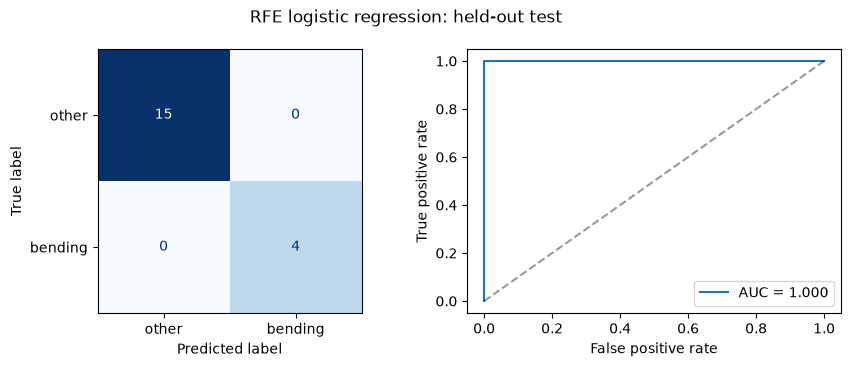

{'accuracy': 1.0, 'balanced_accuracy': 1.0, 'AUC': 1.0}
Selected l=1; the test set uses identical segmentation and training-fitted transformations.
CV accuracy: 0.986; test accuracy: 1.000.
Only 19 test recordings are available, so one mistake changes accuracy by about 5.3 percentage points.


In [9]:
rfe_test_metrics = binary_report(y_binary_test,
    rfe_model.predict_proba(X_test[l_rfe])[:, 1], "RFE logistic regression: held-out test")
print(f"Selected l={l_rfe}; the test set uses identical segmentation and training-fitted transformations.")
print(f"CV accuracy: {best_rfe['score']:.3f}; test accuracy: {rfe_test_metrics['accuracy']:.3f}.")
print("Only 19 test recordings are available, so one mistake changes accuracy by about 5.3 percentage points.")

#### vi. Separation

The selected three features strictly separate all 69 training records: every signed training margin is positive. This establishes complete separation in the selected feature space. The GLM also reports a perfect-separation warning. Consequently, the unpenalized finite maximum-likelihood estimate does not exist, and the displayed numerical GLM Wald p-values (near 1) are unreliable rather than evidence that the features are irrelevant.

The large-$C$ scikit-learn fit gives finite numerical coefficients and correct predictions on all 19 test records, but this does not make unpenalized inference valid. Regularization in part (b) provides a more stable fitting objective.

#### vii. Imbalance and Case-Control Sampling

The original training set has 9 bending and 60 other recordings. A classifier always predicting other would already achieve 60/69 = 87.0% training accuracy. The class supports, together with minority-class recall in the confusion matrices, reveal this imbalance.

I keep all 9 bending cases and randomly sample 9 controls without replacement, using the previously selected feature set. This is sampling within the training set only. To correct the altered class prior, I adjust the sampled model's intercept:

$$\beta_{0,\mathrm{adjusted}}=\beta_{0,\mathrm{sample}}+
\operatorname{logit}(\pi_{\mathrm{train}})-\operatorname{logit}(\pi_{\mathrm{sample}}).$$

This uses training prevalence as the target prevalence, assumes random sampling within each class and a correctly specified logistic model, and keeps slopes unchanged. With only 18 sampled records, estimates can still be unstable; prevalence correction does not remove separation or small-sample effects.

Sampled class counts: [9 9]
Intercept correction: -1.8971


,sampled_coefficient,adjusted_coefficient
intercept,-20.491796,-22.388916
q3_s1_part1,-6.717119,-6.717119
min_s5_part1,12.087441,12.087441
max_s5_part1,15.426732,15.426732


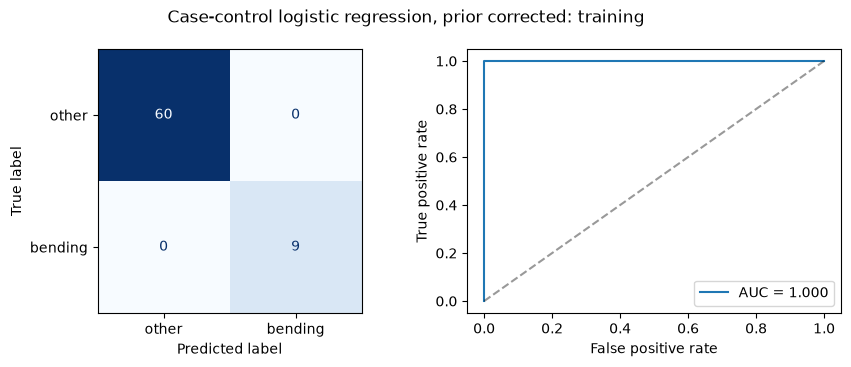

{'accuracy': 1.0, 'balanced_accuracy': 1.0, 'AUC': 1.0}


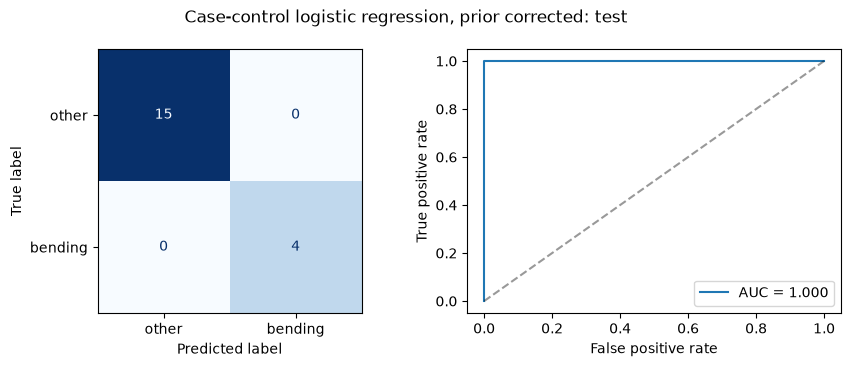

{'accuracy': 1.0, 'balanced_accuracy': 1.0, 'AUC': 1.0}
Adding a constant to the log-odds changes the 0.5-threshold predictions, but not ranking or AUC.


In [10]:
rng = np.random.default_rng(SEED)
cases = np.flatnonzero(y_binary == 1)
controls = rng.choice(np.flatnonzero(y_binary == 0), size=len(cases), replace=False)
sampled_ids = np.r_[cases, controls]
case_control = LogisticRegression(C=1e6, solver="lbfgs", max_iter=2000)
case_control.fit(Z_train[sampled_ids], y_binary[sampled_ids])
prior_correction = logit(y_binary.mean()) - logit(y_binary[sampled_ids].mean())
print("Sampled class counts:", np.bincount(y_binary[sampled_ids]))
print("Intercept correction:", round(prior_correction, 4))
display(pd.DataFrame({"sampled_coefficient": np.r_[case_control.intercept_, case_control.coef_.ravel()],
                      "adjusted_coefficient": np.r_[case_control.intercept_ + prior_correction,
                                                     case_control.coef_.ravel()]},
                     index=["intercept"] + list(selected_names)))
cc_train_metrics = binary_report(y_binary,
    expit(case_control.decision_function(Z_train) + prior_correction),
    "Case-control logistic regression, prior corrected: training")
cc_test_metrics = binary_report(y_binary_test,
    expit(case_control.decision_function(Z_test) + prior_correction),
    "Case-control logistic regression, prior corrected: test")
print("Adding a constant to the log-odds changes the 0.5-threshold predictions, but not ranking or AUC.")

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

Tune $l=1,\ldots,20$ and $C\in\{0.01,0.1,1,10,100\}$ jointly with the same stratified 5-fold splits. Smaller $C$ means stronger L1 regularization. Scaling remains inside the pipeline; LIBLINEAR is used for binary L1 logistic regression.

Best l: 11 Parameters: {'model__C': 1}
Best mean CV accuracy: 0.9857


,l,model__C,CV_accuracy,CV_std
52,11,1.0,0.985714,0.028571
53,11,10.0,0.985714,0.028571
57,12,1.0,0.985714,0.028571
58,12,10.0,0.985714,0.028571
88,18,10.0,0.985714,0.028571
2,1,1.0,0.971429,0.034993
62,13,1.0,0.971429,0.034993
87,18,1.0,0.971429,0.034993
92,19,1.0,0.971429,0.034993
93,19,10.0,0.971429,0.034993


Nonzero coefficients: 8


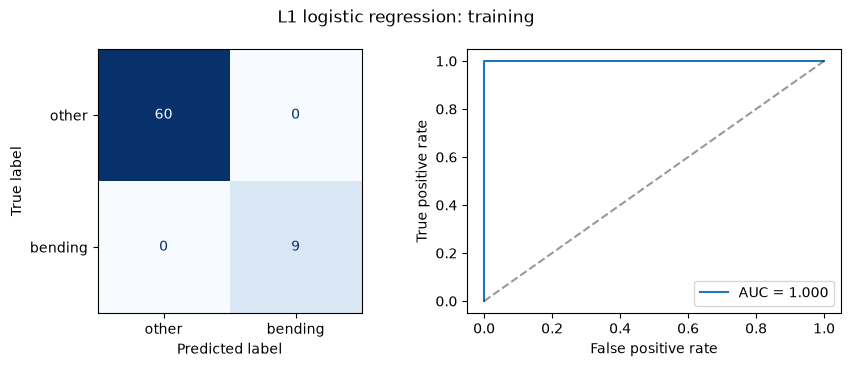

{'accuracy': 1.0, 'balanced_accuracy': 1.0, 'AUC': 1.0}


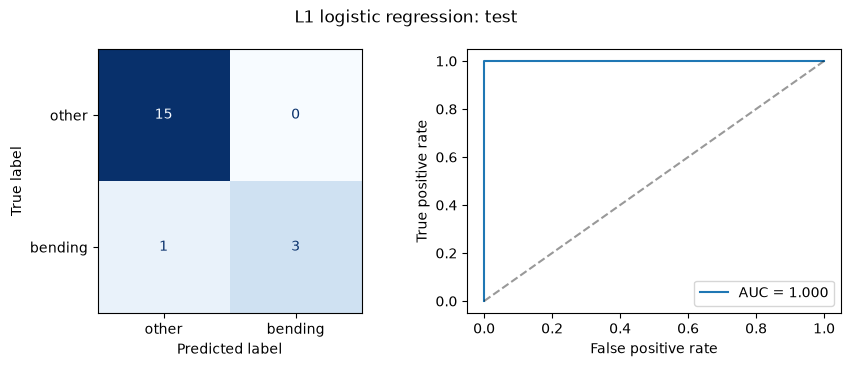

{'accuracy': 0.9473684210526315, 'balanced_accuracy': 0.875, 'AUC': 1.0}


,l,CV_accuracy,accuracy,balanced_accuracy,AUC
method,,,,,
RFE + logistic,1,0.9857,1.0000,1.000,1.0
L1 logistic,11,0.9857,0.9474,0.875,1.0


In [11]:
l1_pipeline = Pipeline([
    ("nonconstant", VarianceThreshold()),
    ("scale", StandardScaler()),
    ("model", LogisticRegression(penalty="l1", solver="liblinear",
                                 max_iter=5000, random_state=SEED))
])
best_l1, l1_results = search_segments(
    l1_pipeline, {"model__C": C_grid}, y_binary, cv_binary)
l_l1 = best_l1["l"]
l1_model = best_l1["model"]
print("Nonzero coefficients:", np.count_nonzero(l1_model.named_steps["model"].coef_))
l1_train_metrics = binary_report(y_binary,
    l1_model.predict_proba(X_train[l_l1])[:, 1], "L1 logistic regression: training")
l1_test_metrics = binary_report(y_binary_test,
    l1_model.predict_proba(X_test[l_l1])[:, 1], "L1 logistic regression: test")

binary_comparison = pd.DataFrame([
    {"method": "RFE + logistic", "l": l_rfe, "CV_accuracy": best_rfe["score"], **rfe_test_metrics},
    {"method": "L1 logistic", "l": l_l1, "CV_accuracy": best_l1["score"], **l1_test_metrics}
]).set_index("method")
display(binary_comparison.round(4))

#### ii. Comparison

Both RFE and L1 achieved mean 5-fold CV accuracy **98.57%**. RFE selected $l=1$ and $p=3$, while L1 selected $l=11$ and $C=1$, retaining eight nonzero coefficients. On the held-out set, RFE correctly classified **19/19 (100%)**, while L1 correctly classified **18/19 (94.74%)**, missing one bending case. Both achieved test AUC **1.0**: L1 ranked the classes correctly but made one error at the 0.5 probability threshold.

Thus RFE performed better on test accuracy in this run, with equal tuning CV accuracy and test AUC. L1 was simpler to implement because shrinkage and selection occur in one fit; RFE repeatedly refits a model. The permitted RFE alternative was used in part (a), so this is an RFE-versus-L1 comparison rather than an implemented p-value-pruning comparison. L1 also avoids relying on unstable ordinary p-values under separation. A one-record difference on this small test set is weak evidence of general superiority.

### (c) Multi-class Classification (The Realistic Case)

#### i. L1-Penalized Multinomial Logistic Regression

There are seven labels, keeping bending1 and bending2 distinct. I tune $l$ and $C$ with **stratified 4-fold CV**, since bending2 has only four training records. Five folds would leave one validation fold without that class. SAGA supports a genuine joint multinomial L1 model; LIBLINEAR does not.

A multiclass confusion matrix has true classes in rows and predicted classes in columns. For ROC, I treat each class as positive versus the other six classes (one-vs-rest). Macro AUC is the equally weighted average of these class-specific AUCs. ROC uses continuous probabilities, not predicted labels.

Best l: 2 Parameters: {'model__C': 100}
Best mean CV accuracy: 0.9126


,l,model__C,CV_accuracy,CV_std
9,2,100.0,0.912582,0.030251
2,1,1.0,0.900327,0.070754
4,1,100.0,0.898693,0.024673
8,2,10.0,0.898693,0.024673
14,3,100.0,0.897876,0.026886
19,4,100.0,0.897876,0.049528
7,2,1.0,0.886438,0.103533
3,1,10.0,0.883987,0.002830
13,3,10.0,0.883170,0.042758
18,4,10.0,0.869281,0.049345


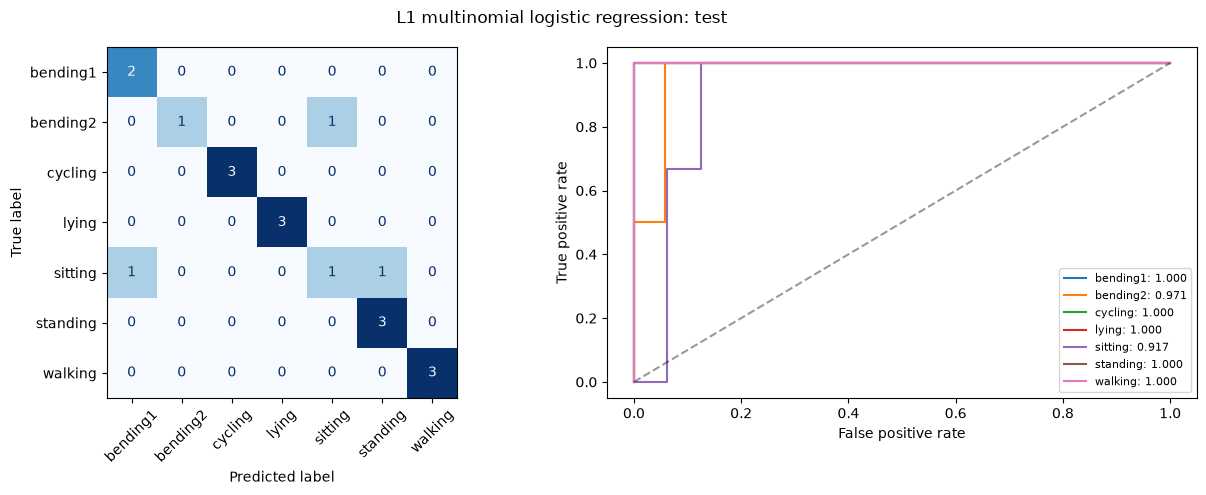

{'accuracy': 0.8421052631578947, 'test_error': 0.1578947368421053, 'macro_OvR_AUC': 0.9838935574229692}
              precision    recall  f1-score   support

    bending1       0.67      1.00      0.80         2
    bending2       1.00      0.50      0.67         2
     cycling       1.00      1.00      1.00         3
       lying       1.00      1.00      1.00         3
     sitting       0.50      0.33      0.40         3
    standing       0.75      1.00      0.86         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.84        19
   macro avg       0.85      0.83      0.82        19
weighted avg       0.85      0.84      0.83        19



,OvR_AUC
class,
bending1,1.0000
bending2,0.9706
cycling,1.0000
lying,1.0000
sitting,0.9167
standing,1.0000
walking,1.0000


In [12]:
def multiclass_report(model, l, title):
    probability = model.predict_proba(X_test[l])
    prediction = model.predict(X_test[l])
    classes = model.classes_
    target = label_binarize(y_test, classes=classes)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    ConfusionMatrixDisplay.from_predictions(y_test, prediction, labels=classes,
        ax=axes[0], xticks_rotation=45, cmap="Blues", colorbar=False)
    auc_rows = []
    for j, label in enumerate(classes):
        fpr, tpr, _ = roc_curve(target[:, j], probability[:, j])
        auc = roc_auc_score(target[:, j], probability[:, j])
        auc_rows.append({"class": label, "OvR_AUC": auc})
        axes[1].plot(fpr, tpr, label=f"{label}: {auc:.3f}")
    axes[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
    axes[1].set(xlabel="False positive rate", ylabel="True positive rate")
    axes[1].legend(fontsize=8, loc="lower right")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    accuracy = accuracy_score(y_test, prediction)
    result = {"accuracy": accuracy, "test_error": 1 - accuracy,
              "macro_OvR_AUC": roc_auc_score(target, probability, average="macro")}
    print(result)
    print(classification_report(y_test, prediction, labels=classes, zero_division=0))
    display(pd.DataFrame(auc_rows).set_index("class").round(4))
    return result

multi_pipeline = Pipeline([
    ("nonconstant", VarianceThreshold()),
    ("scale", StandardScaler()),
    ("model", LogisticRegression(penalty="l1", solver="saga", tol=1e-3,
                                 max_iter=10000, random_state=SEED))
])
best_multi, multi_results = search_segments(
    multi_pipeline, {"model__C": C_grid}, y_train, cv_multi)
multi_metrics = multiclass_report(best_multi["model"], best_multi["l"],
                                  "L1 multinomial logistic regression: test")

#### ii. Naive Bayes

GaussianNB models each feature's class-conditional distribution as Gaussian. MultinomialNB models nonnegative count-like features; neither name describes a Gaussian versus multinomial **class prior**. These continuous summaries are not genuine counts, so MultinomialNB is an approximate baseline requested by the assignment.

Both methods tune $l$ on the same stratified 4-fold splits. GaussianNB also tunes variance smoothing. MultinomialNB tunes additive smoothing and uses fold-fitted MinMax scaling to keep values nonnegative (`clip=True` also bounds future values). These transformations are fitted only on each training fold.

Best l: 1 Parameters: {'model__var_smoothing': 1e-06}
Best mean CV accuracy: 0.8848


,l,model__var_smoothing,CV_accuracy,CV_std
5,2,1.000000e-03,0.884804,0.038207
1,1,1.000000e-06,0.884804,0.056479
2,1,1.000000e-03,0.870915,0.072099
0,1,1.000000e-09,0.870098,0.046697
3,2,1.000000e-09,0.856209,0.061487
4,2,1.000000e-06,0.856209,0.061487
8,3,1.000000e-03,0.797386,0.026549
11,4,1.000000e-03,0.784314,0.067924
14,5,1.000000e-03,0.783497,0.042758
17,6,1.000000e-03,0.782680,0.024181


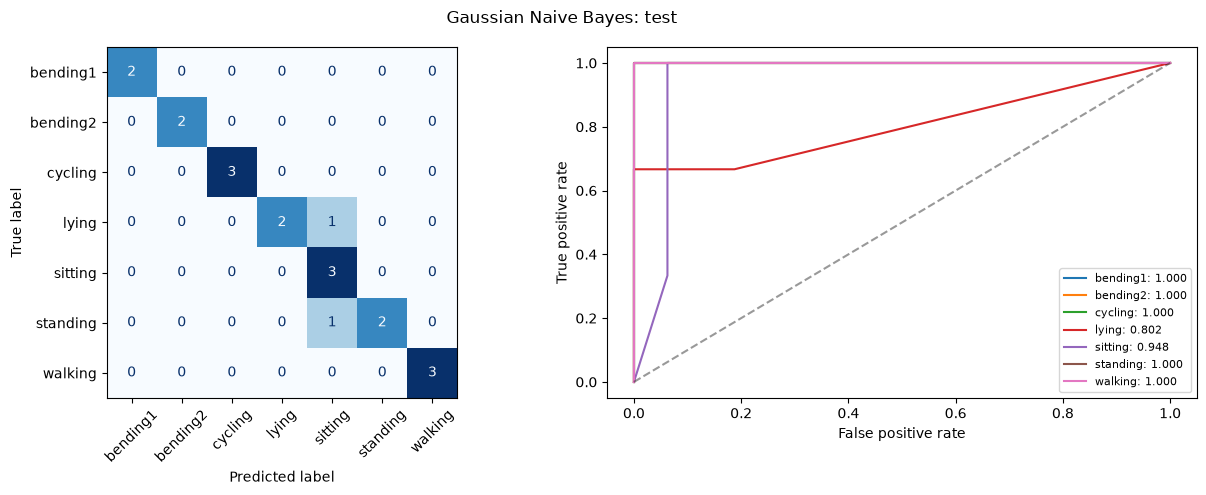

{'accuracy': 0.8947368421052632, 'test_error': 0.10526315789473684, 'macro_OvR_AUC': 0.9642857142857143}
              precision    recall  f1-score   support

    bending1       1.00      1.00      1.00         2
    bending2       1.00      1.00      1.00         2
     cycling       1.00      1.00      1.00         3
       lying       1.00      0.67      0.80         3
     sitting       0.60      1.00      0.75         3
    standing       1.00      0.67      0.80         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.89        19
   macro avg       0.94      0.90      0.91        19
weighted avg       0.94      0.89      0.90        19



,OvR_AUC
class,
bending1,1.0000
bending2,1.0000
cycling,1.0000
lying,0.8021
sitting,0.9479
standing,1.0000
walking,1.0000


Best l: 1 Parameters: {'model__alpha': 0.01}
Best mean CV accuracy: 0.8268


,l,model__alpha,CV_accuracy,CV_std
0,1,0.01,0.826797,0.123363
37,10,0.10,0.825980,0.083297
4,2,0.01,0.812092,0.046071
56,15,0.01,0.812092,0.085515
64,17,0.01,0.812092,0.085515
72,19,0.01,0.812092,0.085515
76,20,0.01,0.811275,0.064801
1,1,0.10,0.798203,0.118470
45,12,0.10,0.798203,0.118470
5,2,0.10,0.797386,0.064537


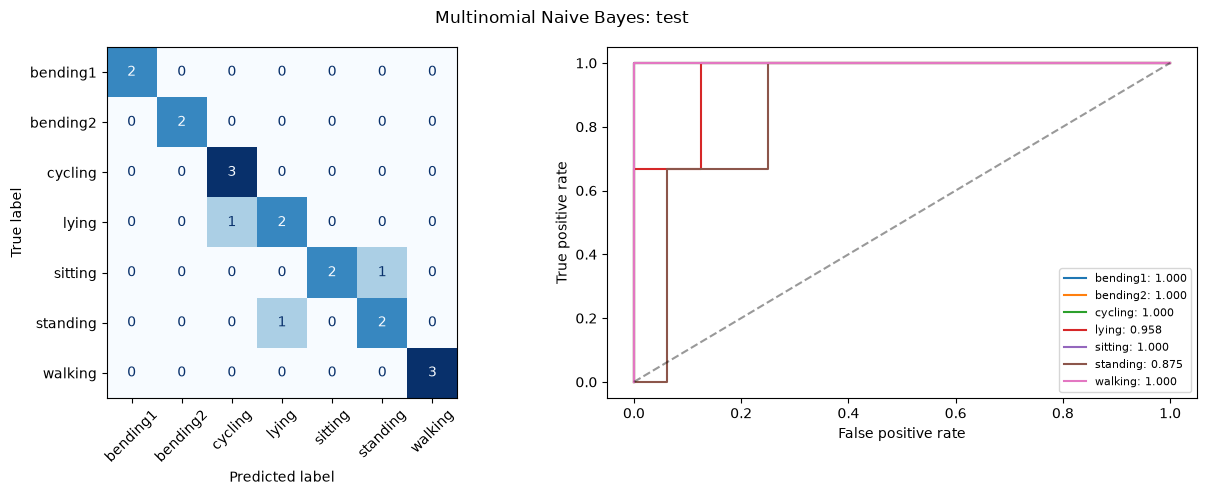

{'accuracy': 0.8421052631578947, 'test_error': 0.1578947368421053, 'macro_OvR_AUC': 0.9761904761904763}
              precision    recall  f1-score   support

    bending1       1.00      1.00      1.00         2
    bending2       1.00      1.00      1.00         2
     cycling       0.75      1.00      0.86         3
       lying       0.67      0.67      0.67         3
     sitting       1.00      0.67      0.80         3
    standing       0.67      0.67      0.67         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.84        19
   macro avg       0.87      0.86      0.86        19
weighted avg       0.86      0.84      0.84        19



,OvR_AUC
class,
bending1,1.0000
bending2,1.0000
cycling,1.0000
lying,0.9583
sitting,1.0000
standing,0.8750
walking,1.0000


,l,CV_accuracy,accuracy,test_error,macro_OvR_AUC
method,,,,,
L1 multinomial logistic,2,0.9126,0.8421,0.1579,0.9839
Gaussian NB,1,0.8848,0.8947,0.1053,0.9643
Multinomial NB,1,0.8268,0.8421,0.1579,0.9762


In [13]:
gaussian_pipeline = Pipeline([
    ("nonconstant", VarianceThreshold()),
    ("scale", StandardScaler()),
    ("model", GaussianNB())
])
best_gaussian, gaussian_results = search_segments(
    gaussian_pipeline, {"model__var_smoothing": [1e-9, 1e-6, 1e-3]}, y_train, cv_multi)
gaussian_metrics = multiclass_report(best_gaussian["model"], best_gaussian["l"],
                                     "Gaussian Naive Bayes: test")

multinomial_pipeline = Pipeline([
    ("nonconstant", VarianceThreshold()),
    ("scale", MinMaxScaler(clip=True)),
    ("model", MultinomialNB())
])
best_multinomial, multinomial_results = search_segments(
    multinomial_pipeline, {"model__alpha": [0.01, 0.1, 1, 10]}, y_train, cv_multi)
multinomial_metrics = multiclass_report(best_multinomial["model"], best_multinomial["l"],
                                        "Multinomial Naive Bayes: test")

multi_comparison = pd.DataFrame([
    {"method": "L1 multinomial logistic", "l": best_multi["l"],
     "CV_accuracy": best_multi["score"], **multi_metrics},
    {"method": "Gaussian NB", "l": best_gaussian["l"],
     "CV_accuracy": best_gaussian["score"], **gaussian_metrics},
    {"method": "Multinomial NB", "l": best_multinomial["l"],
     "CV_accuracy": best_multinomial["score"], **multinomial_metrics}
]).set_index("method")
display(multi_comparison.round(4))

#### iii. Comparison

**Gaussian Naive Bayes achieved the lowest observed test error:** 2/19 = **10.53%** (accuracy 89.47%), using $l=1$ and variance smoothing $10^{-6}$. Multinomial NB selected $l=1$ and alpha 0.01 and made 3/19 errors (**15.79%**), so Gaussian NB performed better than Multinomial NB by test accuracy.

L1 multinomial logistic regression selected $l=2$, $C=100$ and also made 3/19 errors (**15.79%**). It had the highest training CV accuracy (**91.26%**, versus Gaussian NB's **88.48%** and Multinomial NB's **82.68%**) and the highest test macro OvR AUC (**0.9839**, versus **0.9643** and **0.9762**).

Therefore, Gaussian NB is best **by observed test accuracy**, while multinomial logistic regression is best **by tuning CV accuracy and test macro AUC**. Gaussian NB's continuous-feature model is more appropriate here than Multinomial NB's count model, although NB's conditional-independence assumption is imperfect for correlated summaries. All hyperparameters were chosen using training CV, without retuning on the test set. The test-accuracy gap is only one recording, so it does not establish that Gaussian NB will generally perform best.

## 3. ISLR 4.8.3

For QDA with one predictor, let $\pi_k=P(Y=k)$ and $X\mid Y=k\sim N(\mu_k,\sigma_k^2)$. Bayes' rule assigns $x$ to the class maximizing $\pi_k f_k(x)$. Taking logarithms and dropping the common $-\tfrac12\log(2\pi)$ term gives

$$\delta_k(x)=\log\pi_k-\log\sigma_k-\frac{(x-\mu_k)^2}{2\sigma_k^2}.$$

Expanding,

$$\delta_k(x)=-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_k}{\sigma_k^2}x
-\frac{\mu_k^2}{2\sigma_k^2}
-\log\sigma_k+\log\pi_k.$$

For classes $k$ and $j$, the boundary solves $\delta_k(x)-\delta_j(x)=0$. The coefficient of $x^2$ is $\frac{1}{2\sigma_j^2}-\frac{1}{2\sigma_k^2}$, which generally does not cancel when variances differ. Thus the discriminant comparison and decision boundary equation are **quadratic**. Equal variances are the special case in which this quadratic term disappears, yielding the linear LDA comparison.

## 4. ISLR 4.8.7

Let $Y=\mathrm{Yes}$ mean that a company issues a dividend. The given quantities are

$$\pi_{\mathrm{Yes}}=0.8,\quad \pi_{\mathrm{No}}=0.2,\quad
\mu_{\mathrm{Yes}}=10,\quad \mu_{\mathrm{No}}=0,\quad \sigma^2=36.$$

By Bayes' rule,

$$P(\mathrm{Yes}\mid X=4)
=\frac{0.8 f_{\mathrm{Yes}}(4)}{0.8 f_{\mathrm{Yes}}(4)+0.2 f_{\mathrm{No}}(4)}.$$

The common normalizing constants cancel. Since $(4-10)^2=36$ and $(4-0)^2=16$,

$$P(\mathrm{Yes}\mid X=4)
=\frac{0.8e^{-36/72}}{0.8e^{-36/72}+0.2e^{-16/72}}
\approx 0.7519.$$

The predicted probability is **75.19%**, so a 0.5-threshold classifier predicts **Yes**.